In [1]:
import os
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams['font.sans-serif'] = 'Arial'

In [2]:
data_file = "womens_clothing_classification_dataset.csv"
if not os.path.exists(data_file):
    data_file = os.path.join("03-11-2026", "Task 1", "womens_clothing_classification_dataset.csv")

df = pd.read_csv(data_file)
df['Full_Review_Text'] = df['Full_Review_Text'].fillna('')
print(f"Loaded Women's Clothing Review Dataset: {df.shape[0]:,} rows across {df.shape[1]} attributes.")

Loaded Women's Clothing Review Dataset: 23,486 rows across 23 attributes.


In [3]:
bundle_path = "models_dict.pkl"
if not os.path.exists(bundle_path):
    bundle_path = os.path.join("03-11-2026", "Task 1", "models_dict.pkl")

with open(bundle_path, 'rb') as f:
    bundle = pickle.load(f)

vectorizer = bundle['vectorizer']
models = bundle['models']
metrics = bundle['metrics']
feature_names = bundle['feature_names']

print("Successfully loaded serialized model artifacts:")
for name in models.keys():
    print(f" - {name}")

Successfully loaded serialized model artifacts:
 - Logistic Regression
 - Multinomial Naive Bayes
 - Linear SVM (Calibrated SGD)
 - Random Forest Classifier


In [4]:
benchmark_df = pd.read_csv("multimodel_evaluation_benchmark_metrics.csv") if os.path.exists("multimodel_evaluation_benchmark_metrics.csv") else pd.read_csv(os.path.join("03-11-2026", "Task 1", "multimodel_evaluation_benchmark_metrics.csv"))
display(benchmark_df)

,Model_Name,Accuracy,Precision,Recall,F1_Score,Macro_F1,ROC_AUC,Training_Time_s,Inference_Latency_ms
0,Logistic Regression,0.9029,0.9154,0.9718,0.9427,0.8122,0.9354,0.23,0.0004
1,Multinomial Naive Bayes,0.8740,0.8759,0.9865,0.9279,0.7135,0.9310,0.01,0.0011
2,Linear SVM (Calibrated SGD),0.8938,0.8997,0.9801,0.9382,0.7808,0.9348,0.08,0.0005
3,Random Forest Classifier,0.8304,0.8295,0.9990,0.9064,0.5009,0.9112,2.75,0.0418


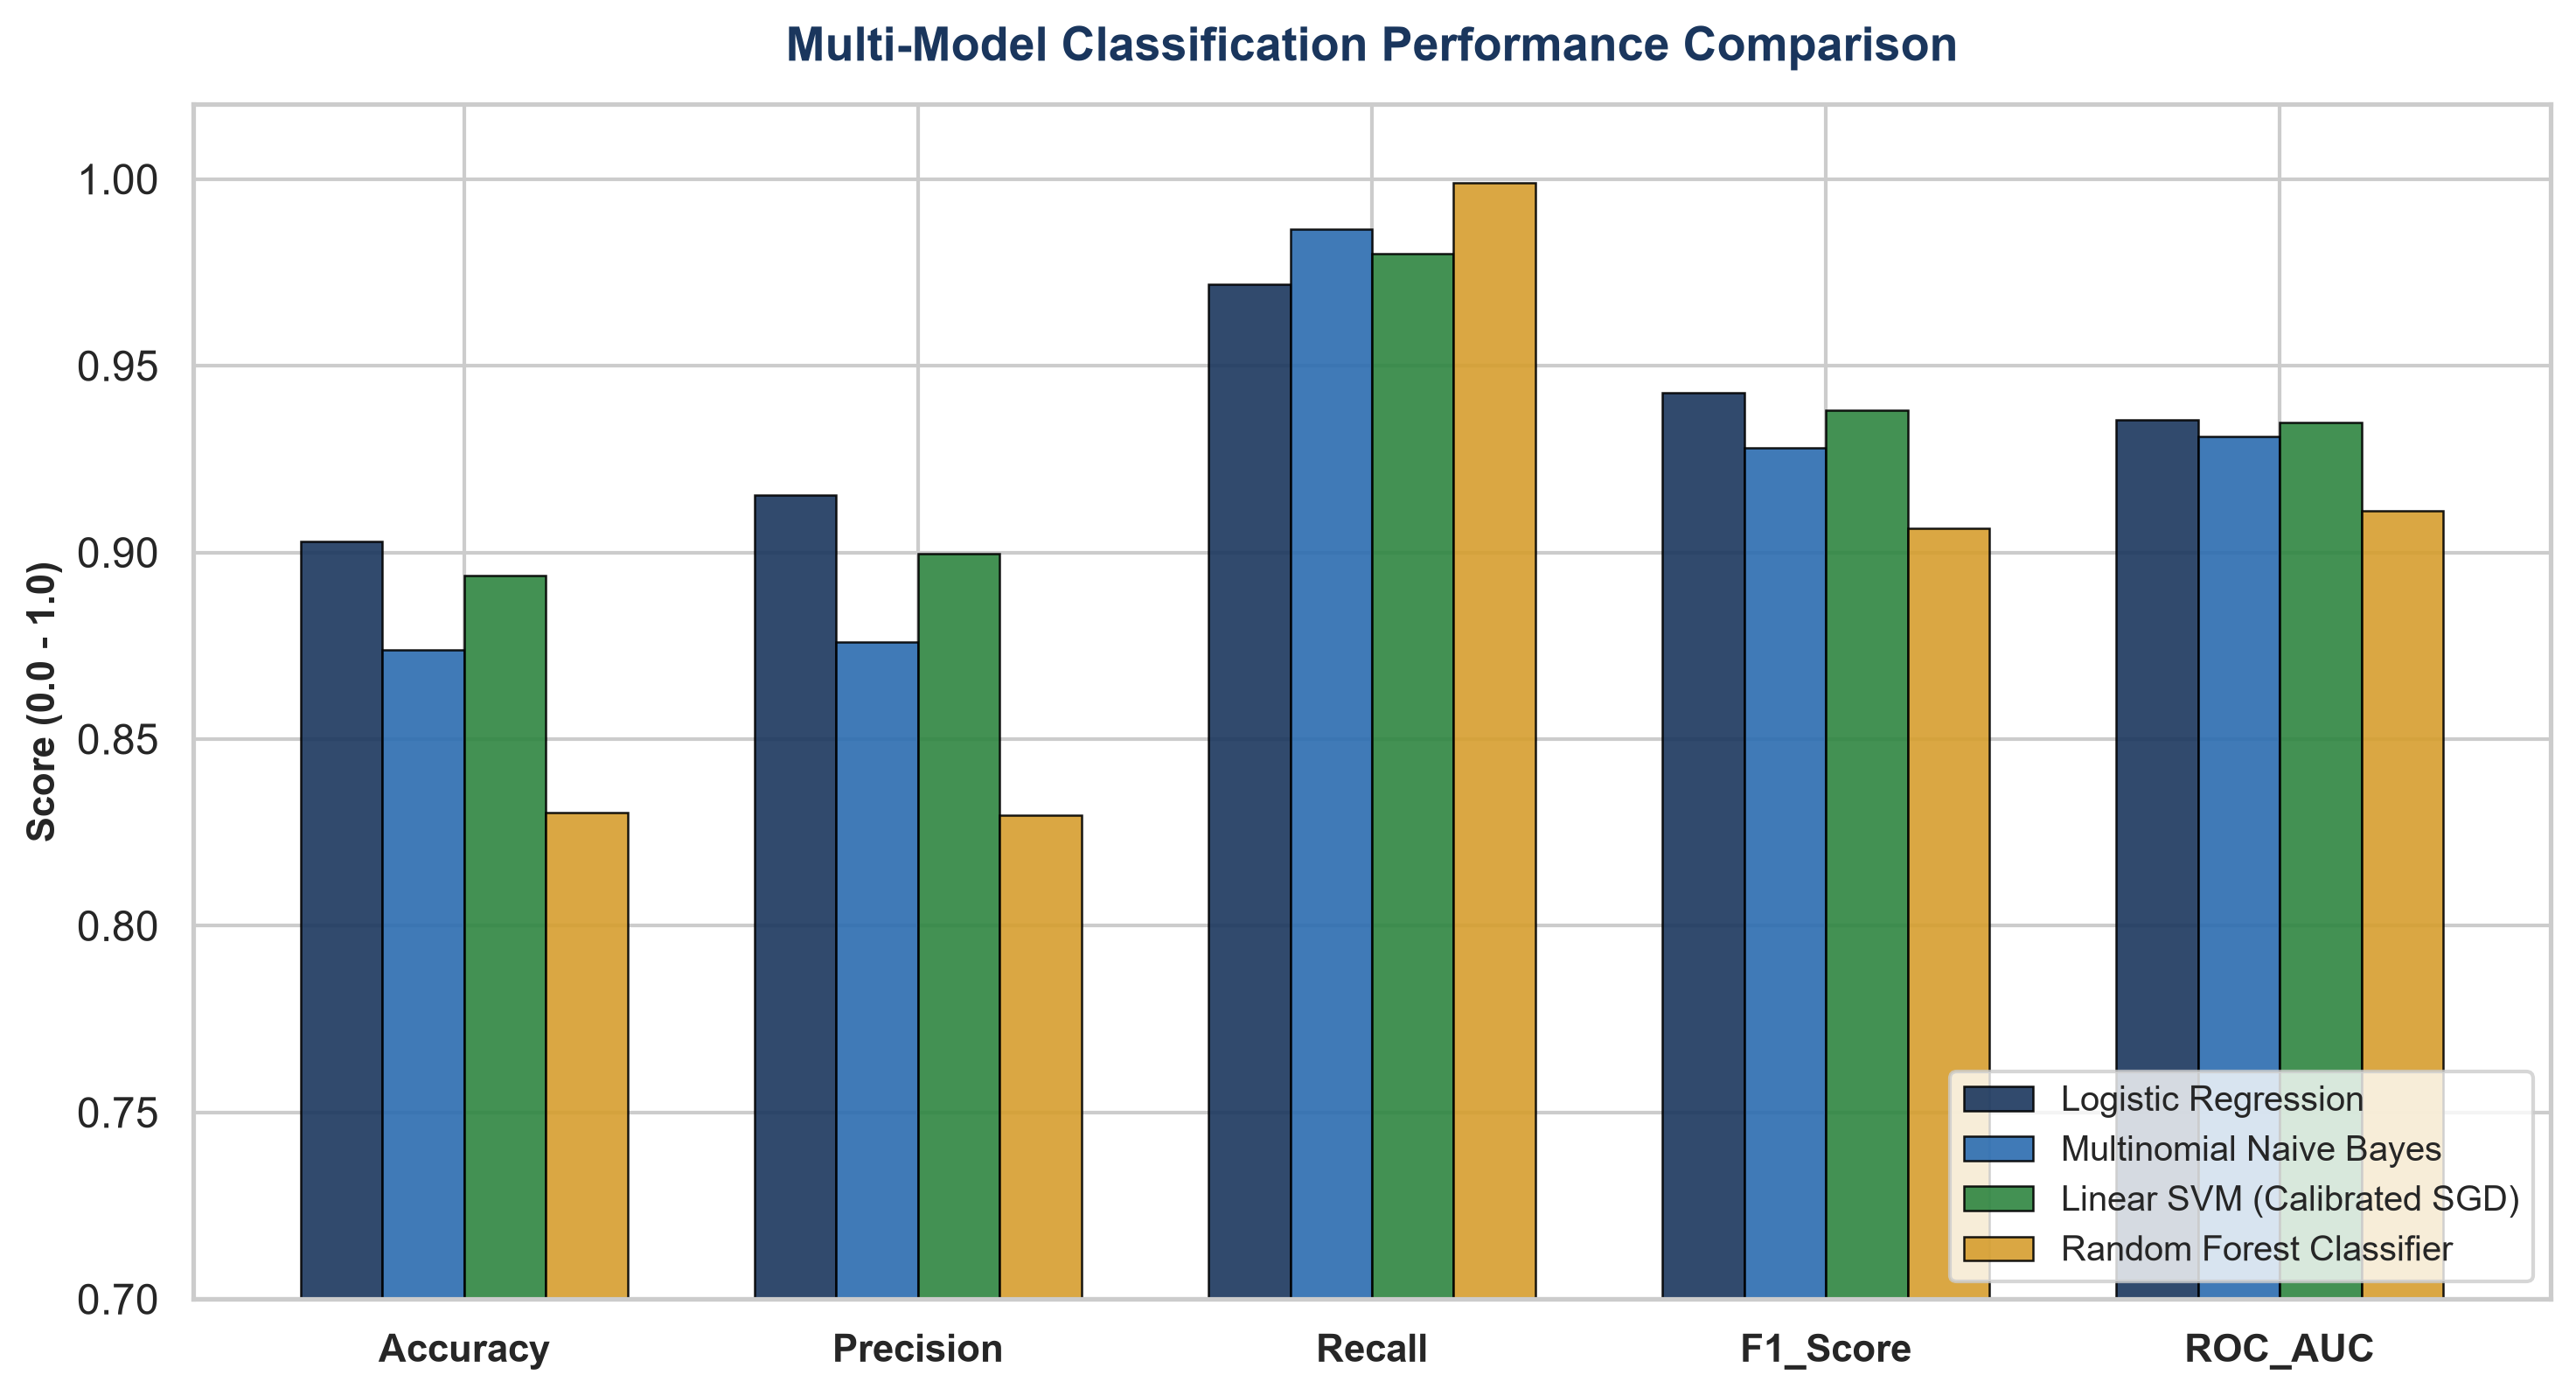

In [5]:
fig, ax = plt.subplots(figsize=(10, 5.5), dpi=300)
categories = ['Accuracy', 'Precision', 'Recall', 'F1_Score', 'ROC_AUC']
x = np.arange(len(categories))
width = 0.18
palette = ['#1A365D', '#2B6CB0', '#2E8540', '#D69E2E']

for i, (m_name, color) in enumerate(zip(benchmark_df['Model_Name'], palette)):
    row = benchmark_df[benchmark_df['Model_Name'] == m_name].iloc[0]
    vals = [row[c] for c in categories]
    ax.bar(x + i*width, vals, width, label=m_name, color=color, alpha=0.9, edgecolor='black', linewidth=0.6)

ax.set_title("Multi-Model Classification Performance Comparison", fontsize=13, fontweight='bold', pad=12, color='#1A365D')
ax.set_ylabel("Score (0.0 - 1.0)", fontsize=10.5, fontweight='bold')
ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(categories, fontsize=10.5, fontweight='bold')
ax.set_ylim(0.70, 1.02)
ax.legend(loc='lower right', frameon=True, fontsize=9.5)
plt.tight_layout()
plt.show()

In [6]:
samples_df = pd.read_csv("prediction_confidence_sample_results.csv") if os.path.exists("prediction_confidence_sample_results.csv") else pd.read_csv(os.path.join("03-11-2026", "Task 1", "prediction_confidence_sample_results.csv"))
display(samples_df.head(10))

,Sample_ID,Review_Snippet,Model_Name,Predicted_Label,Recommendation_Probability,Confidence_Score,Certainty_Band
0,1,Absolutely love this gorgeous dress! The fabri...,Logistic Regression,Recommended,0.9781,0.9781,High
1,1,Absolutely love this gorgeous dress! The fabri...,Multinomial Naive Bayes,Recommended,0.9651,0.9651,High
2,1,Absolutely love this gorgeous dress! The fabri...,Linear SVM (Calibrated SGD),Recommended,0.9553,0.9553,High
3,1,Absolutely love this gorgeous dress! The fabri...,Random Forest Classifier,Recommended,0.8607,0.8607,High
4,2,"Cute top and lovely color, but the chest area ...",Logistic Regression,Recommended,0.7499,0.7499,Moderate
5,2,"Cute top and lovely color, but the chest area ...",Multinomial Naive Bayes,Recommended,0.7589,0.7589,Moderate
6,2,"Cute top and lovely color, but the chest area ...",Linear SVM (Calibrated SGD),Recommended,0.7463,0.7463,Moderate
7,2,"Cute top and lovely color, but the chest area ...",Random Forest Classifier,Recommended,0.8216,0.8216,High
8,3,Worst purchase ever. Poor thin scratchy materi...,Logistic Regression,Not Recommended,0.0436,0.9564,High
9,3,Worst purchase ever. Poor thin scratchy materi...,Multinomial Naive Bayes,Not Recommended,0.0708,0.9292,High


In [7]:
explain_df = pd.read_csv("lime_shap_feature_importance_weights.csv") if os.path.exists("lime_shap_feature_importance_weights.csv") else pd.read_csv(os.path.join("03-11-2026", "Task 1", "lime_shap_feature_importance_weights.csv"))
display(explain_df.head(10))

,Token,Coefficient_Weight,TFIDF_Weight,SHAP_Additive_Attribution,Contribution_Direction
0,love,5.2768,0.1526,0.8052,Supports Recommendation
1,gorgeous,2.7319,0.2873,0.7850,Supports Recommendation
2,perfection,1.4500,0.4570,0.6626,Supports Recommendation
3,fabric,-3.0654,0.2028,-0.6218,Opposes Recommendation
4,flattering,1.4306,0.2139,0.3060,Supports Recommendation
5,luxurious,0.4973,0.5225,0.2598,Supports Recommendation
6,absolutely,0.6060,0.3211,0.1946,Supports Recommendation
7,fit,-0.8738,0.1707,-0.1492,Opposes Recommendation
8,dress,0.2651,0.1728,0.0458,Supports Recommendation
9,drape,-0.0313,0.4042,-0.0126,Opposes Recommendation


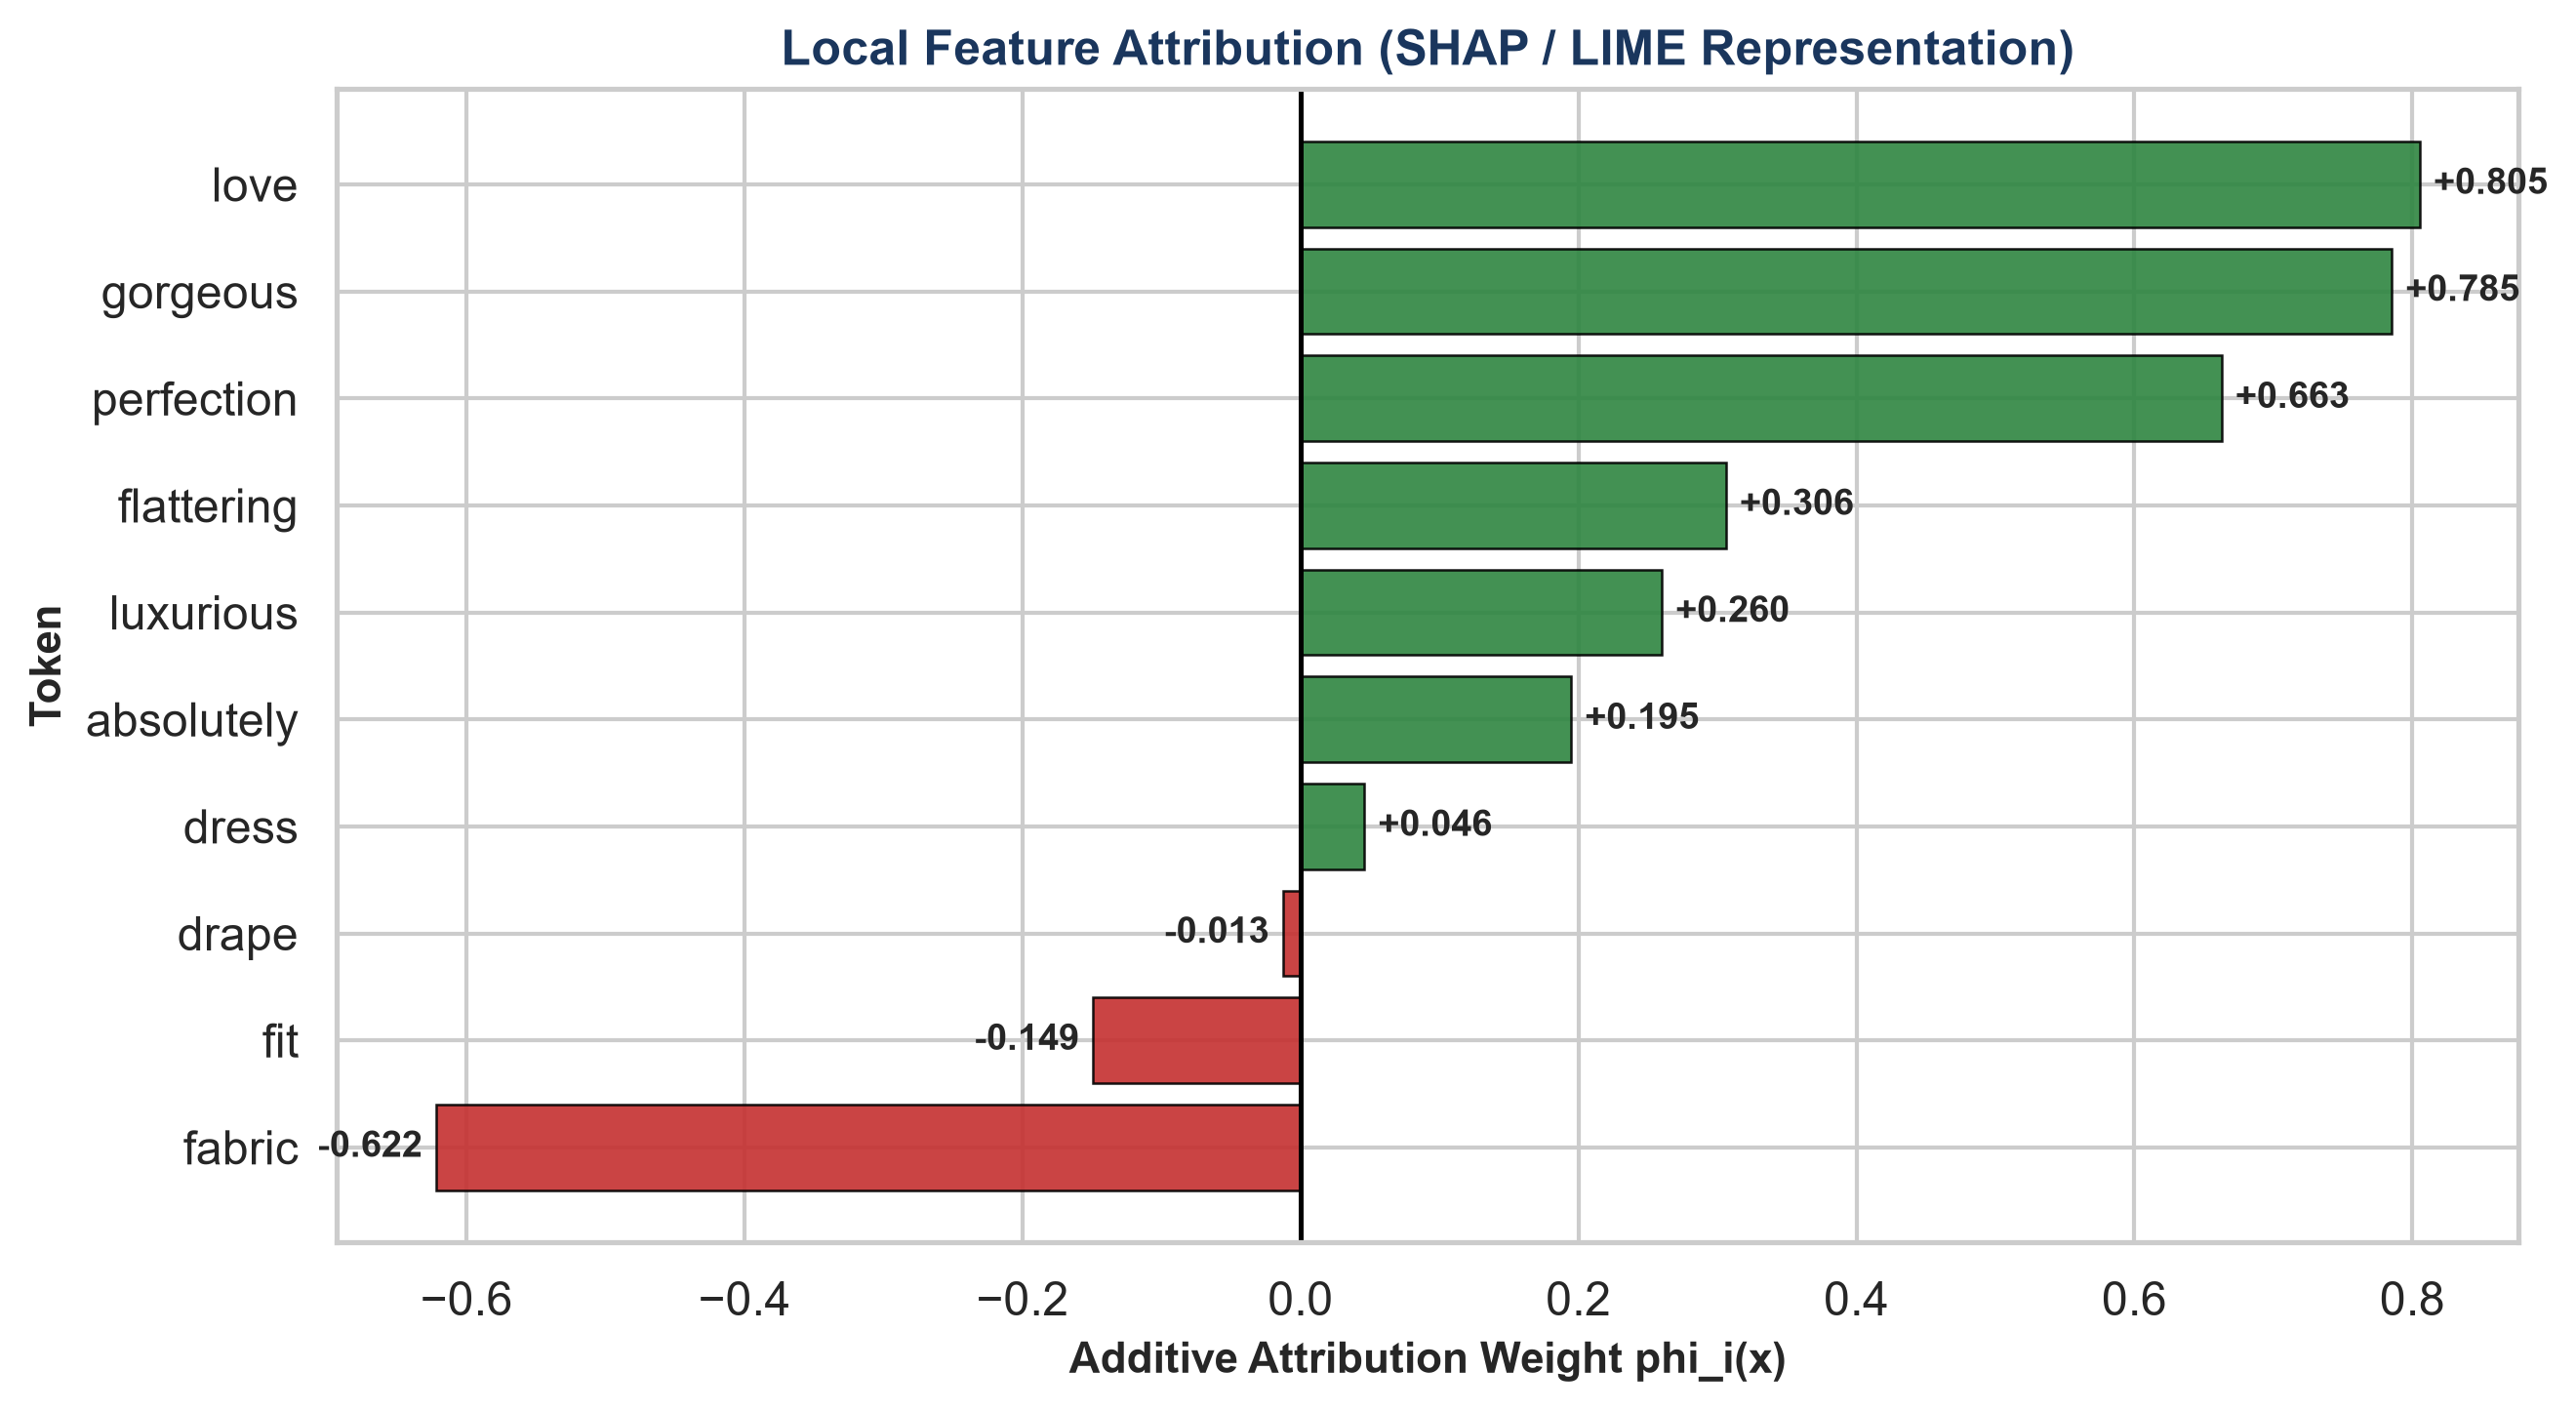

In [8]:
fig, ax = plt.subplots(figsize=(9, 5), dpi=300)
top_words = explain_df.head(10).sort_values(by='SHAP_Additive_Attribution', ascending=True)
bar_colors = ['#2E8540' if val > 0 else '#C53030' for val in top_words['SHAP_Additive_Attribution']]
bars = ax.barh(top_words['Token'], top_words['SHAP_Additive_Attribution'], color=bar_colors, alpha=0.9, edgecolor='black', linewidth=0.6)

ax.axvline(0, color='black', linewidth=1.2)
ax.set_title("Local Feature Attribution (SHAP / LIME Representation)", fontsize=12, fontweight='bold', color='#1A365D')
ax.set_xlabel("Additive Attribution Weight phi_i(x)", fontsize=10.5, fontweight='bold')
ax.set_ylabel("Token", fontsize=10.5, fontweight='bold')

for bar in bars:
    w_val = bar.get_width()
    x_pos = w_val + (0.01 if w_val >= 0 else -0.01)
    ha = 'left' if w_val >= 0 else 'right'
    ax.text(x_pos, bar.get_y() + bar.get_height()/2, f"{w_val:+.3f}", va='center', ha=ha, fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()